# EDA on Retail Sales Data
**Objective:** Explore retail sales data to uncover patterns, customer behaviour trends and actionable business insights.

**Tech stack:** Python, pandas, matplotlib, seaborn

> **Note:** `retail_sales.csv` is a practice dataset. For your final submission, repeat the same steps on a real Kaggle dataset (search "Superstore Sales") by changing the file path in Section 1 and adjusting column names.

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Load data and initial inspection
_Checklist: shape, column dtypes, null check_

In [2]:
df = pd.read_csv("retail_sales.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Age,Gender,Region,Category,Product,Unit_Price,Quantity,Discount,Sales,Profit
0,ORD-100770,2022-01-01,CUST-1544,33,Male,West,Clothing,Winter Jacket,139.13,1,0.05,132.17,23.16
1,ORD-103387,2022-01-01,CUST-1632,32,Female,South,Technology,Smartwatch,186.42,3,0.00,559.26,122.60
2,ORD-102749,2022-01-01,CUST-1307,52,Male,West,Furniture,Standing Desk,473.55,1,0.00,473.55,52.50
3,ORD-100418,2022-01-02,CUST-1756,25,Female,South,Technology,Bluetooth Speaker,64.26,3,0.30,134.95,-14.08
4,ORD-104276,2022-01-02,CUST-1411,18,Female,South,Office Supplies,Stapler,10.07,2,0.00,20.14,6.37


In [ ]:
print("Shape:", df.shape)
print()
df.info()

In [3]:
print("Null values per column:")
df.isnull().sum()

Null values per column:


Order_ID        0
Order_Date      0
Customer_ID     0
Customer_Age    0
Gender          0
Region          0
Category        0
Product         0
Unit_Price      0
Quantity        0
Discount        0
Sales           0
Profit          0
dtype: int64

**Observation:** _How many rows and columns are there? Are there any nulls? Is `Order_Date` stored as the right type?_

In [4]:
# Convert the date column to datetime and create helper columns
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Quarter"] = df["Order_Date"].dt.quarter
df["YearMonth"] = df["Order_Date"].dt.to_period("M")
df.dtypes

Order_ID                   str
Order_Date      datetime64[us]
Customer_ID                str
Customer_Age             int64
Gender                     str
Region                     str
Category                   str
Product                    str
Unit_Price             float64
Quantity                 int64
Discount               float64
Sales                  float64
Profit                 float64
Year                     int32
Month                    int32
Quarter                  int32
YearMonth            period[M]
dtype: object

## 2. Descriptive statistics
_Checklist: mean, median, mode, standard deviation for all numerical columns_

In [5]:
num_cols = df.select_dtypes(include="number").columns.drop(["Year", "Month", "Quarter"])
stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
stats["mode"] = [df[c].mode()[0] for c in num_cols]
stats.round(2)

,mean,median,std,min,max,mode
Customer_Age,36.34,36.00,11.10,18.00,75.00,18.00
Unit_Price,63.13,41.02,82.14,4.75,485.38,5.39
Quantity,2.27,2.00,1.33,1.00,6.00,1.00
Discount,0.07,0.00,0.09,0.00,0.30,0.00
Sales,137.66,55.88,228.96,3.36,2792.04,4.98
Profit,17.58,7.71,35.95,-424.48,444.68,1.94


**Observation:** _Compare mean and median of `Sales` and `Profit`. If the mean is much higher than the median, what does that tell you about the distribution?_

## 3. Time series analysis
_Checklist: monthly and quarterly sales trends with line charts_

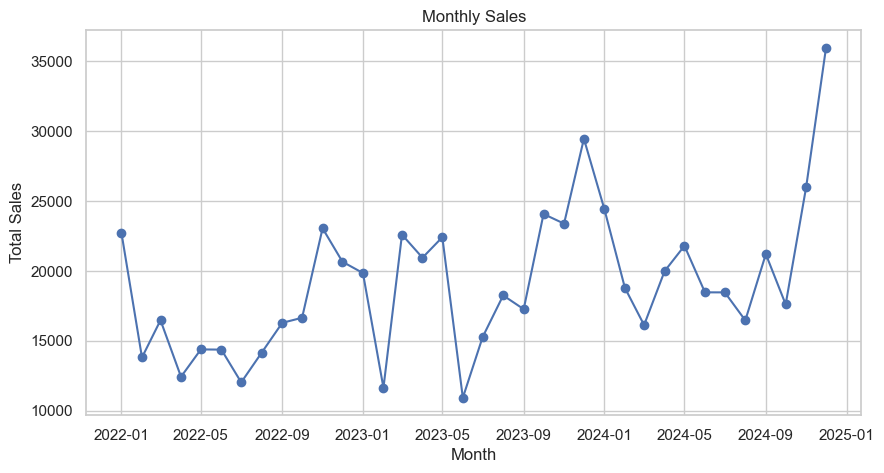

In [6]:
monthly = df.groupby("YearMonth")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

**Observation:** _Write 2-3 sentences here about what this chart/output shows. What stands out? Why might it be happening?_

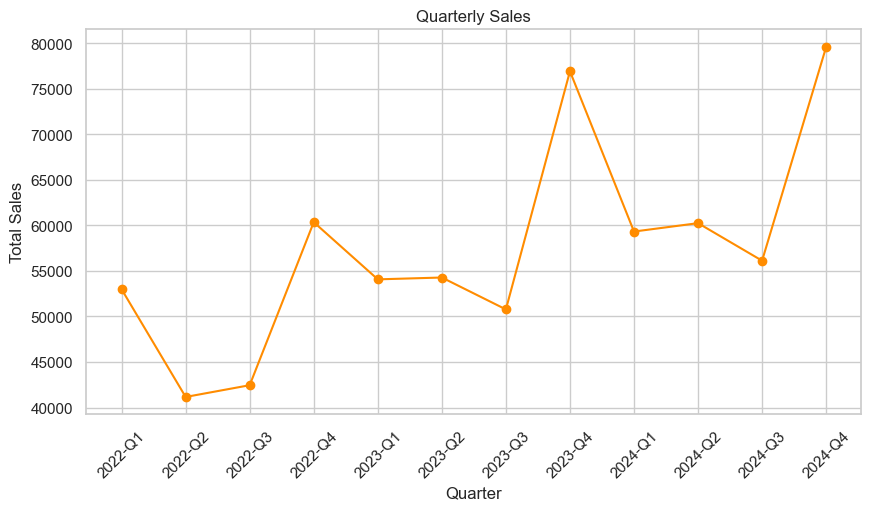

In [7]:
quarterly = df.groupby(["Year", "Quarter"])["Sales"].sum().reset_index()
quarterly["Period"] = quarterly["Year"].astype(str) + "-Q" + quarterly["Quarter"].astype(str)

plt.plot(quarterly["Period"], quarterly["Sales"], marker="o", color="darkorange")
plt.title("Quarterly Sales")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

**Observation:** _Write 2-3 sentences here about what this chart/output shows. What stands out? Why might it be happening?_

## 4. Customer demographics
_Checklist: age group distribution, gender breakdown_

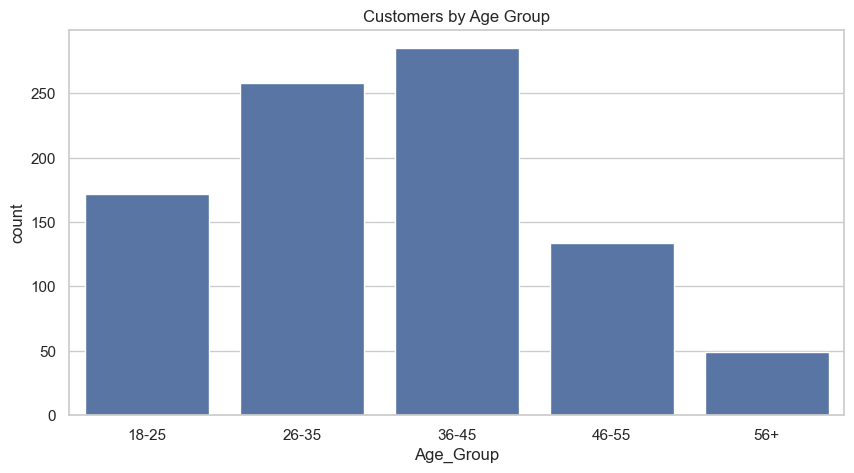

In [8]:
customers = df.drop_duplicates("Customer_ID")[["Customer_ID", "Customer_Age", "Gender"]].copy()
bins = [17, 25, 35, 45, 55, 100]
labels = ["18-25", "26-35", "36-45", "46-55", "56+"]
customers["Age_Group"] = pd.cut(customers["Customer_Age"], bins=bins, labels=labels)

sns.countplot(data=customers, x="Age_Group", order=labels)
plt.title("Customers by Age Group")
plt.show()

**Observation:** _Write 2-3 sentences here about what this chart/output shows. What stands out? Why might it be happening?_

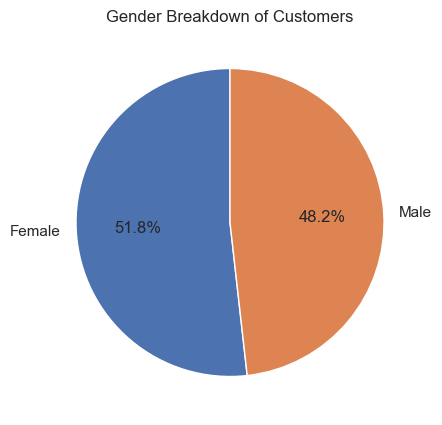

In [9]:
gender_counts = customers["Gender"].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Gender Breakdown of Customers")
plt.show()

**Observation:** _Write 2-3 sentences here about what this chart/output shows. What stands out? Why might it be happening?_

## 5. Product analysis
_Checklist: top 10 best-selling products, revenue by category (bar chart)_

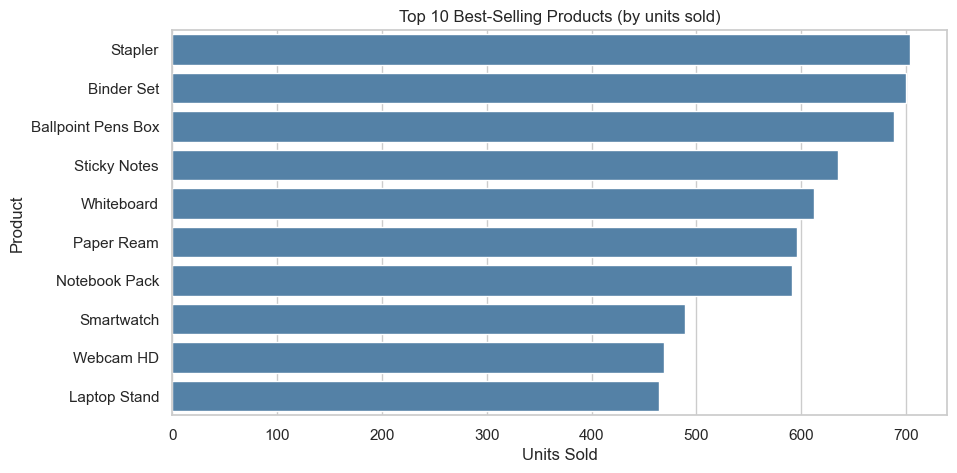

In [10]:
top_products = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False).head(10)

sns.barplot(x=top_products.values, y=top_products.index, color="steelblue")
plt.title("Top 10 Best-Selling Products (by units sold)")
plt.xlabel("Units Sold")
plt.show()

**Observation:** _Write 2-3 sentences here about what this chart/output shows. What stands out? Why might it be happening?_

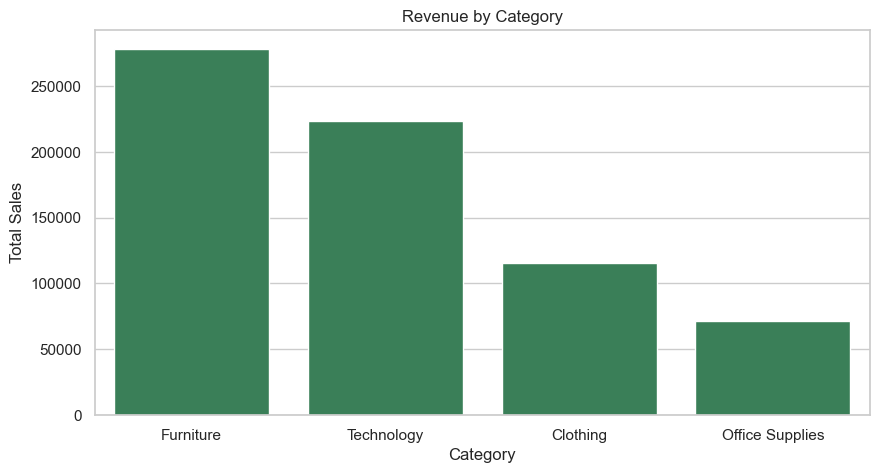

In [11]:
cat_rev = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

sns.barplot(x=cat_rev.index, y=cat_rev.values, color="seagreen")
plt.title("Revenue by Category")
plt.ylabel("Total Sales")
plt.show()

**Observation:** _Write 2-3 sentences here about what this chart/output shows. What stands out? Why might it be happening?_

## 6. Correlation heatmap
_Checklist: correlation matrix between numerical variables_

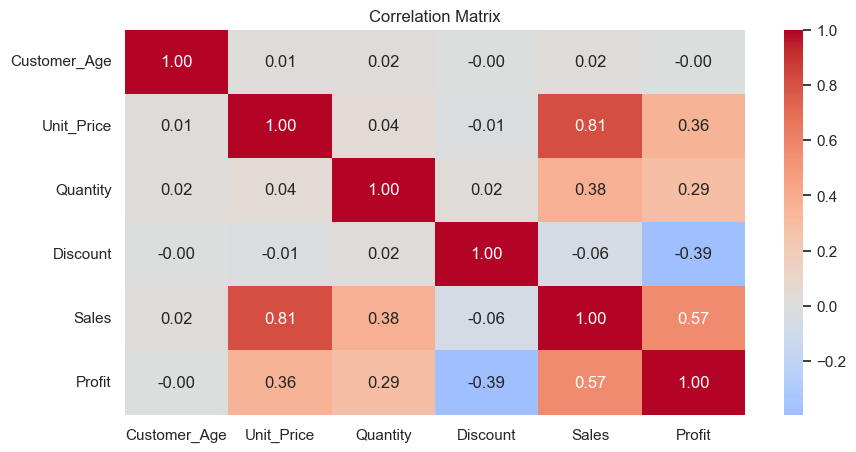

In [12]:
corr = df[["Customer_Age", "Unit_Price", "Quantity", "Discount", "Sales", "Profit"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

**Observation:** _Which variables are strongly correlated? Pay attention to `Discount` vs `Profit`. Does correlation here imply causation?_

## 7. Additional visualisation (non-obvious insight)
_Checklist: at least one extra chart of your choice. Example below: does discounting hurt profit?_

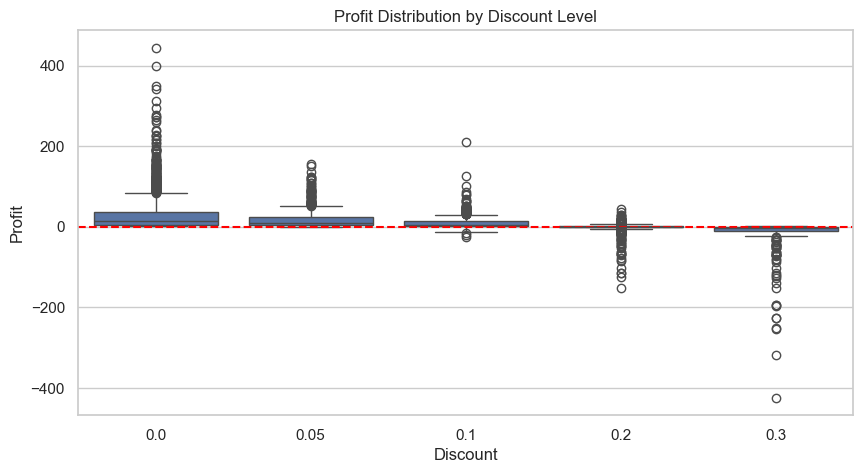

In [13]:
sns.boxplot(data=df, x="Discount", y="Profit")
plt.title("Profit Distribution by Discount Level")
plt.axhline(0, color="red", linestyle="--")
plt.show()

**Observation:** _What happens to profit as the discount grows? Try making your own additional chart too, for example profit by category and region, or a monthly profit trend._

## 8. Conclusion and business recommendations
_Checklist: at least 3 specific, actionable recommendations based on your findings_

Fill this in using your **own** findings above. Format suggestion:

1. **Finding:** ... **Recommendation:** ...
2. **Finding:** ... **Recommendation:** ...
3. **Finding:** ... **Recommendation:** ...